
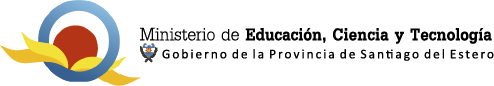

# Clase 1: Introduccion al deep learning. TP1

## Materia: Sistemas de Inteligencia Artificial

## Tema: Forward Propagation.

## Contenidos:

* Red Neuronal Artificial
* Forward Propagation (Propagación hacia adelante)




## Introducción:


En este laboratorio, construiremos una red neuronal desde cero y programaremos cómo realiza predicciones utilizando la propagación hacia adelante. Ten en cuenta que todas las bibliotecas de aprendizaje profundo ya tienen implementados los procesos completos de entrenamiento y predicción, por lo que en la práctica no sería necesario construir una red neuronal desde cero. Sin embargo, completar este laboratorio te ayudará a comprender mejor las redes neuronales y cómo funcionan.

# Objetivo de este jupyter notebook:

* Construir una red neuronal

* Calcular la suma ponderada en cada nodo

* Calcular la activación de los nodos

* Usar la propagación hacia adelante para propagar los datos

# Repaso:



A partir de los videos, repasemos cómo una red neuronal realiza predicciones mediante el proceso de propagación hacia adelante. Aquí tenemos una red neuronal que toma dos entradas, tiene una capa oculta con dos nodos y una capa de salida con un nodo.


<img src="http://cocl.us/neural_network_example" alt="Neural Network Example" width="600px">


Comencemos inicializando aleatoriamente los pesos y los sesgos en la red. Tenemos 6 pesos y 3 sesgos: uno para cada nodo en la capa oculta, así como para cada nodo en la capa de salida.

In [1]:
#Todas las bibliotecas necesarias para este laboratorio se enumeran a continuación.
#Las bibliotecas preinstaladas en Skills Network Labs están comentadas.

#!pip install numpy==1.26.4

In [2]:
import numpy as np # importar la biblioteca Numpy para generar

weights = np.around(np.random.uniform(size=6), decimals=2) # inicializar los pesos
biases = np.around(np.random.uniform(size=3), decimals=2)  # inicializar los sesgos


Imprimamos los pesos y los sesgos como verificación de control.


In [3]:
print(weights)
print(biases)

[0.77 0.05 0.19 0.9  0.25 0.35]
[0.56 0.99 0.2 ]


Ahora que tenemos definidos los pesos y los sesgos de la red, calculemos la salida para una entrada dada, $x_1$ y $x_2$.

In [4]:
x_1 = 0.5 # entrada 1
x_2 = 0.85 # entrada 2

print('x1 es {} y x2 es {}'.format(x_1, x_2))


x1 es 0.5 y x2 es 0.85


Comencemos calculando la suma ponderada de las entradas, $z_{1,1}$, en el primer nodo de la capa oculta.

In [5]:
z_11 = x_1 * weights[0] + x_2 * weights[1] + biases[0]

print('La suma ponderada de las entradas en el primer nodo de la capa oculta es {}'.format(z_11))


La suma ponderada de las entradas en el primer nodo de la capa oculta es 0.9875


A continuación, calculemos la suma ponderada de las entradas, $z_{1, 2}$, en el segundo nodo de la capa oculta. Asigna el valor a **z_12**.

In [10]:
z_12 = x_1 * weights[2] + x_2 * weights[3] + biases[1]

Imprimir la suma ponderada.


In [6]:
print('La suma ponderada de las entradas en el segundo nodo de la capa oculta es {}'.format(np.around(z_12, decimals=4)))

NameError: name 'z_12' is not defined

A continuación, asumiendo una función de activación sigmoide, calculemos la activación del primer nodo, $a_{1, 1}$, en la capa oculta.


In [ ]:
a_11 = 1.0 / (1.0 + np.exp(-z_11))

print('La activación del primer nodo en la capa oculta es {}'.format(np.around(a_11, decimals=4)))


Calculemos también la activación del segundo nodo, $a_{1, 2}$, en la capa oculta. Asigna el valor a **a_12**.


In [11]:
a_12 = 1.0 / (1.0 + np.exp(-z_12))

Imprime la activación del segundo nodo


In [ ]:
print('La activación del segundo nodo en la capa oculta es {}'.format(np.around(a_12, decimals=4)))


Ahora estas activaciones servirán como entradas para la capa de salida. Por lo tanto, calculemos la suma ponderada de estas entradas para el nodo en la capa de salida. Asigna el valor a **z_2**.

In [ ]:
### escribe tu respuesta aquí

z_2 = a_11 * weights[4] + a_12 * weights[5] + biases[2]

Haz doble clic __aquí__ para ver la solución.

<!-- La respuesta correcta es: z_2 = a_11 * weights[4] + a_12 * weights[5] + biases[2] -->

Imprime la suma ponderada de las entradas en el nodo de la capa de salida.


In [ ]:
print('La suma ponderada de las entradas en el nodo de la capa de salida es {}'.format(np.around(z_2, decimals=4)))

Finalmente, calculemos la salida de la red como la activación del nodo en la capa de salida. Asigna el valor a **a_2**.



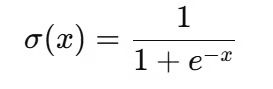
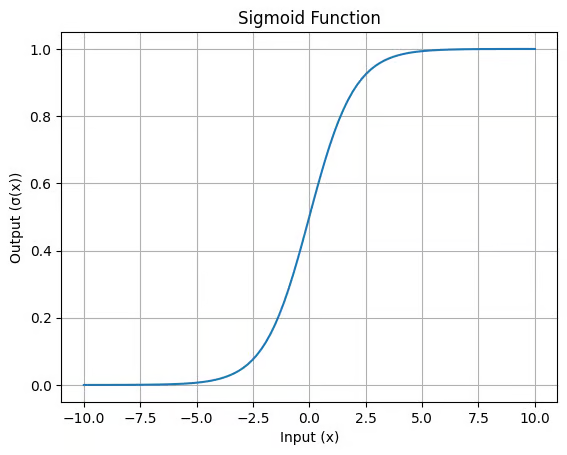

In [ ]:
a_2 = 1.0 / (1.0 + np.exp(-z_2))

print('La activación del nodo en la capa de salida es {}'.format(np.around(a_2, decimals=4)))

Imprime la activación del nodo en la capa de salida, que equivale a la predicción realizada por la red.



In [ ]:
print('La salida de la red para x1 = 0.5 y x2 = 0.85 es {}'.format(np.around(a_2, decimals=4)))


<hr>


Obviamente, las redes neuronales para problemas reales están compuestas por muchas capas ocultas y muchos más nodos en cada capa. Por lo tanto, no podemos continuar haciendo predicciones usando este enfoque tan ineficiente de calcular manualmente la suma ponderada en cada nodo y la activación de cada nodo.

Para programar una forma automática de hacer predicciones, vamos a generalizar nuestra red. Una red general tomaría $n$ entradas, tendría varias capas ocultas, cada capa oculta con $m$ nodos, y contaría con una capa de salida. Aunque la red muestra una sola capa oculta, programaremos la red para que pueda tener varias capas ocultas. De manera similar, aunque la red muestra una capa de salida con un nodo, programaremos la red para que pueda tener más de un nodo en la capa de salida.


<img src="http://cocl.us/general_neural_network" alt="Neural Network General" width="600px">


<a id='item12'></a>


##  Construir una red neuronal


Comencemos definiendo formalmente la estructura de la red.

In [ ]:
n = 2 # número de entradas
num_hidden_layers = 2 # número de capas ocultas
m = [2, 2] # número de nodos en cada capa oculta
num_nodes_output = 1 # número de nodos en la capa de salida


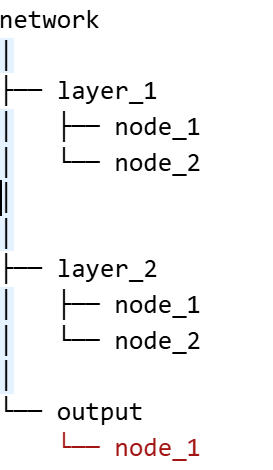

Ahora que hemos definido la estructura de la red, procedamos a inicializar los pesos y los sesgos de la red con números aleatorios. Para poder inicializar los pesos y los sesgos con números aleatorios, necesitaremos importar la biblioteca **Numpy**.

In [ ]:
import numpy as np # importar la biblioteca Numpy

num_nodes_previous = n # número de nodos en la capa anterior

network = {} # inicializar la red como un diccionario vacío

# recorrer cada capa e inicializar aleatoriamente los pesos y sesgos asociados a cada nodo
# observa cómo agregamos 1 al número de capas ocultas para incluir la capa de salida
for layer in range(num_hidden_layers + 1):

    # determinar el nombre de la capa
    if layer == num_hidden_layers:
        layer_name = 'output'
        num_nodes = num_nodes_output
    else:
        layer_name = 'layer_{}'.format(layer + 1)
        num_nodes = m[layer]

    # inicializar pesos y sesgos asociados a cada nodo en la capa actual
    network[layer_name] = {}
    for node in range(num_nodes):
        node_name = 'node_{}'.format(node+1)
        network[layer_name][node_name] = {
            'weights': np.around(np.random.uniform(size=num_nodes_previous), decimals=2),
            'bias': np.around(np.random.uniform(size=1), decimals=2),
        }

    num_nodes_previous = num_nodes

print(network) # imprimir la red


¡Genial! Con el código anterior, ahora podemos inicializar los pesos y los sesgos para cualquier red con cualquier número de capas ocultas y cualquier número de nodos en cada capa. Pero pongamos este código en una función para poder ejecutarlo de manera repetida cada vez que queramos construir una red neuronal.


In [ ]:
def initialize_network(num_inputs, num_hidden_layers, num_nodes_hidden, num_nodes_output):

    num_nodes_previous = num_inputs # número de nodos en la capa anterior

    network = {}

    # recorrer cada capa e inicializar aleatoriamente los pesos y sesgos asociados a cada capa
    for layer in range(num_hidden_layers + 1):

        if layer == num_hidden_layers:
            layer_name = 'output' # nombrar la última capa como capa de salida
            num_nodes = num_nodes_output
        else:
            layer_name = 'layer_{}'.format(layer + 1) # de lo contrario, asignar un número a la capa
            num_nodes = num_nodes_hidden[layer]

        # inicializar pesos y sesgo para cada nodo
        network[layer_name] = {}
        for node in range(num_nodes):
            node_name = 'node_{}'.format(node+1)
            network[layer_name][node_name] = {
                'weights': np.around(np.random.uniform(size=num_nodes_previous), decimals=2),
                'bias': np.around(np.random.uniform(size=1), decimals=2),
            }

        num_nodes_previous = num_nodes

    return network # devolver la red neuronal


### Usa la función **initialize_network** para crear una red que:

* 1 - reciba 5 entradas

* 2 -  tenga tres capas ocultas

* 3 - tenga 3 nodos en la primera capa, 2 nodos en la segunda capa y 3 nodos en la tercera capa

* 4 - tenga 1 nodo en la capa de salida

Llama a la red **small_network**.

In [ ]:
### escribe tu respuesta aquí
small_network = initialize_network(5, 3, [3, 2, 3], 1)


Haz doble clic en __aquí__ para ver la solución.

<!-- La respuesta correcta es:  
small_network = initialize_network(5, 3, [3, 2, 3], 1)  
-->


## Calcular la suma ponderada en cada nodo



La suma ponderada en cada nodo se calcula como el producto punto de las entradas y los pesos, más el sesgo. Así que vamos a crear una función llamada *compute_weighted_sum* que haga exactamente eso.

In [7]:
def compute_weighted_sum(inputs, weights, bias):
    return np.sum(inputs * weights) + bias

Generemos 5 entradas que podamos alimentar a **small_network**.

In [8]:
from random import seed
import numpy as np

np.random.seed(12)
inputs = np.around(np.random.uniform(size=5), decimals=2)

print('Las entradas de la red son {}'.format(inputs))


Las entradas de la red son [0.15 0.74 0.26 0.53 0.01]


#### Usa la función **compute_weighted_sum** para calcular la suma ponderada en el primer nodo de la primera capa oculta.


In [9]:
### escribe tu respuesta aquí

node_weights = small_network['layer_1']['node_1']['weights']
node_bias = small_network['layer_1']['node_1']['bias']

weighted_sum = compute_weighted_sum(inputs, node_weights, node_bias)
print('La suma ponderada en el primer nodo de la capa oculta es {}'.format(np.around(weighted_sum[0], decimals=4)))



NameError: name 'small_network' is not defined

Haz doble clic __aquí__ para ver la solución.

<!-- La respuesta correcta es:  
```python
node_weights = small_network['layer_1']['node_1']['weights']
node_bias = small_network['layer_1']['node_1']['bias']

weighted_sum = compute_weighted_sum(inputs, node_weights, node_bias)
print('La suma ponderada en el primer nodo de la capa oculta es {}'.format(np.around(weighted_sum[0], decimals=4)))
```  
-->


<a id='item14'></a>


## Calcular la activación del nodo




Recuerda que la salida de cada nodo es simplemente una transformación no lineal de la suma ponderada. Usamos funciones de activación para realizar esta transformación. Aquí utilizaremos la función sigmoide como función de activación. Así que definamos una función que tome una suma ponderada como entrada y devuelva la transformación no lineal de la entrada usando la función sigmoide

In [ ]:
def node_activation(weighted_sum):
    return 1.0 / (1.0 + np.exp(-1 * weighted_sum))

#### Usa la función *node_activation* para calcular la salida del primer nodo en la primera capa oculta.


In [ ]:
### escribe tu respuesta aquí
node_output  = node_activation(compute_weighted_sum(inputs, node_weights, node_bias))
print('La salida del primer nodo en la capa oculta es {}'.format(np.around(node_output[0], decimals=4)))



Haz doble clic __aquí__ para ver la solución.

<!-- La respuesta correcta es:  
node_output  = node_activation(compute_weighted_sum(inputs, node_weights, node_bias))  
print('La salida del primer nodo en la capa oculta es {}'.format(np.around(node_output[0], decimals=4)))  
-->


## HASTA AQUÍ LA PRIMERA CLASE

## Forward Propagation


La última parte para construir una red neuronal que pueda realizar predicciones es juntar todo. Por lo tanto, vamos a crear una función que aplique las funciones compute_weighted_sum y node_activation a cada nodo de la red, propague los datos hasta la capa de salida y genere una predicción para cada nodo en la capa de salida.

La forma en que vamos a lograr esto es mediante el siguiente procedimiento:

1. Comenzar con la capa de entrada como entrada
para la primera capa oculta.

2. Calcular la suma ponderada en los nodos de la capa actual.

3. Calcular la salida de los nodos de la capa actual.

4. Establecer la salida de la capa actual como la entrada para la siguiente capa.

5. Pasar a la siguiente capa de la red.

6. Repetir los pasos 2 a 5 hasta calcular la salida de la capa de salida.

In [ ]:
def forward_propagate(network, inputs):

    layer_inputs = list(inputs)  # comenzar con la capa de entrada como entrada para la primera capa oculta

    for layer in network:

        layer_data = network[layer]

        layer_outputs = []
        for layer_node in layer_data:

            node_data = layer_data[layer_node]

            # calcular la suma ponderada y la salida de cada nodo al mismo tiempo
            node_output = node_activation(compute_weighted_sum(layer_inputs, node_data['weights'], node_data['bias']))
            layer_outputs.append(np.around(node_output[0], decimals=4))

        if layer != 'output':
            print('Las salidas de los nodos en la capa oculta número {} son {}'.format(layer.split('_')[1], layer_outputs))

        layer_inputs = layer_outputs  # establecer la salida de esta capa como entrada para la siguiente capa

    network_predictions = layer_outputs
    return network_predictions


#### Usar la función *forward_propagate* para calcular la predicción de nuestra pequeña red


In [ ]:
### escribe tu respuesta aquí
predictions = forward_propagate(small_network, inputs)
print('El valor predicho por la red para la entrada dada es {}'.format(np.around(predictions[0], decimals=4)))



Haz doble clic __aquí__ para ver la solución.

<!-- La respuesta correcta es: predictions = forward_propagate(small_network, inputs) print('El valor predicho por la red para la entrada dada es {}'.format(np.around(predictions[0], decimals=4))) -->

Entonces, construimos el código para definir una red neuronal. Podemos especificar el número de entradas que puede recibir la red neuronal, el número de capas ocultas, así como el número de nodos en cada capa oculta, y el número de nodos en la capa de salida.


Primero usamos *initialize_network* para crear nuestra red neuronal y definir sus pesos y sesgos.


In [ ]:
my_network = initialize_network(5, 3, [2, 3, 2], 3)

Luego, para una entrada determinada

In [ ]:
inputs = np.around(np.random.uniform(size=5), decimals=2)

calculamos las predicciones de la red.


In [ ]:
predictions = forward_propagate(my_network, inputs)
print('Los valores predichos por la red para la entrada dada son {}'.format(predictions))


Siéntete libre de experimentar con el código creando redes de diferentes estructuras y diviértete haciendo predicciones usando la función *forward_propagate*.

In [ ]:
### crear una red neuronal

# Crear una red con 4 entradas, 2 capas ocultas (4 y 3 nodos) y 2 nodos de salida
my_network_2 = initialize_network(4, 2, [4, 3], 2)

# Generar entradas aleatorias para esta red
np.random.seed(42)
inputs_2 = np.around(np.random.uniform(size=4), decimals=2)

print('Entradas:', inputs_2)
print('\nEstructura de la red:')
for layer in my_network_2:
    print(f'  {layer}: {len(my_network_2[layer])} nodo(s)')

# Obtener predicciones
predictions_2 = forward_propagate(my_network_2, inputs_2)
print(f'\nPredicciones: {predictions_2}')

In [ ]:
### crear otra red neuronal

# Crear una red más compleja: 6 entradas, 4 capas ocultas (5, 4, 3, 2 nodos) y 1 nodo de salida
my_network_3 = initialize_network(6, 4, [5, 4, 3, 2], 1)

# Generar entradas aleatorias
np.random.seed(100)
inputs_3 = np.around(np.random.uniform(size=6), decimals=2)

print('Entradas:', inputs_3)
print('\nEstructura de la red:')
for layer in my_network_3:
    print(f'  {layer}: {len(my_network_3[layer])} nodo(s)')

# Obtener predicciones
predictions_3 = forward_propagate(my_network_3, inputs_3)
print(f'\nPredicciones: {predictions_3}')

### ¡Gracias por completar este Práctico!

## Explicación Detallada de la Notebook: Forward Propagation

Esta notebook está meticulosamente diseñada para desglosar y explicar el proceso fundamental de **Propagación hacia Adelante (Forward Propagation)** en las redes neuronales. El objetivo principal es construir una red neuronal desde sus componentes básicos, sin depender de librerías de aprendizaje profundo de alto nivel, lo que permite una comprensión profunda de cómo los datos viajan y se transforman dentro de la red para generar predicciones.

### 1. Encabezado y Contexto Inicial (`qtNxEZkKjUbW`, `ASCUorm1jUbY`)

*   **Propósito**: Establece el contexto del laboratorio como parte de la materia de Sistemas de Inteligencia Artificial, centrándose en el tema de Forward Propagation.
*   **Contenidos**: Enumera los conceptos clave que se explorarán: Red Neuronal Artificial y Propagación hacia Adelante.

### 2. Introducción y Objetivos (`T3Q0moZNjUbZ`, `HD2q9QqyjUbZ`)

*   **Explicación**: Aunque las librerías modernas de Deep Learning (como TensorFlow o PyTorch) abstraen gran parte de estos cálculos, este laboratorio te guía a través de la construcción de una red neuronal desde cero. Este enfoque manual es crucial para entender la mecánica interna.
*   **Objetivos Específicos**: Define claramente lo que lograrás:
    *   Construir una red neuronal básica.
    *   Calcular la suma ponderada en cada nodo (la combinación de entradas, pesos y sesgos).
    *   Calcular la activación de los nodos (aplicar una función no lineal a la suma ponderada).
    *   Utilizar la propagación hacia adelante para mover los datos a través de la red y obtener predicciones.

### 3. Repaso y Ejemplo Manual (`LaWG-tuWjUbZ` a `4_5XWXrpjUbj`)

Esta sección ilustra un ejemplo concreto de forward propagation en una red neuronal pequeña (2 entradas, 2 nodos ocultos, 1 nodo de salida).

*   **Arquitectura de la Red (`M5LHzSp5jUba`, `-VYfdiPajUba`)**:
    *   La imagen provided (`http://cocl.us/neural_network_example`) visualiza una red con dos neuronas en la capa de entrada, dos en la capa oculta y una en la capa de salida.
*   **Inicialización de Parámetros (`UiaAnAi2jUbb`, `wBAKEEi4jUbb`, `Zq-JfJ9JjUbb`, `OiYqpRJljUbc`, `CVly4S2njUbc`)**:
    *   **`import numpy as np`**: Se importa NumPy, esencial para operaciones numéricas, especialmente con arrays.
    *   **`weights = np.around(np.random.uniform(size=6), decimals=2)`**: Se inicializan 6 pesos aleatorios entre 0 y 1, redondeados a dos decimales. Estos `weights` representan la fuerza de las conexiones entre las neuronas y son cruciales para el aprendizaje de la red.
    *   **`biases = np.around(np.random.uniform(size=3), decimals=2)`**: Se inicializan 3 sesgos aleatorios. Los `biases` permiten ajustar el umbral de activación de cada neurona, dando flexibilidad al modelo.
    *   **`print(weights)` y `print(biases)`**: Estos comandos simplemente muestran los valores aleatorios generados para los pesos y sesgos, permitiendo verificar su inicialización.
*   **Entradas de la Red (`BiQIGZyTjUbc`, `-prCSg4-jUbc`)**:
    *   **`x_1 = 0.5` y `x_2 = 0.85`**: Se definen las dos entradas que se propagarán a través de la red. Estas son las características o datos de entrada del modelo.
*   **Cálculos en la Capa Oculta (Nodos 1 y 2)**:
    *   **Suma Ponderada del Primer Nodo (`xhvw3RURjUbc`, `vstXDiC5jUbc`)**:
        *   **`z_11 = x_1 * weights[0] + x_2 * weights[1] + biases[0]`**: Esta es la operación central. Se multiplica cada entrada (`x_1`, `x_2`) por su peso correspondiente (`weights[0]`, `weights[1]`) y se le suma el sesgo (`biases[0]`). `z_11` es la suma ponderada antes de la activación.
    *   **Suma Ponderada del Segundo Nodo (`2N23mdwWjUbc`, `GJVOEOBLjUbc`, `m6hPZYP_jUbd`, `pLIVAFGhjUbd`)**:
        *   **`z_12 = x_1 * weights[2] + x_2 * weights[3] + biases[1]`**: De manera análoga a `z_11`, se calcula la suma ponderada para el segundo nodo oculto, utilizando los pesos (`weights[2]`, `weights[3]`) y el sesgo (`biases[1]`) correspondientes.
    *   **Activación del Primer Nodo (`nQXjbn13jUbd`, `HxjgcW9EjUbd`)**:
        *   **`a_11 = 1.0 / (1.0 + np.exp(-z_11))`**: Se aplica la función de activación sigmoide a `z_11`. La función sigmoide comprime el valor `z_11` a un rango entre 0 y 1, introduciendo no linealidad, lo que permite a la red aprender relaciones complejas.
    *   **Activación del Segundo Nodo (`M6qzR3xEjUbd`, `yncerCgljUbd`, `ghf0EbIqjUbd`, `cQjdSwyajUbd`)**:
        *   **`a_12 = 1.0 / (1.0 + np.exp(-z_12))`**: Similarmente, se aplica la función sigmoide a `z_12` para obtener la activación `a_12`.
*   **Cálculos en la Capa de Salida (`kFgD4qw-jUbd` a `4_5XWXrpjUbj`)**:
    *   **Suma Ponderada del Nodo de Salida (`kFgD4qw-jUbd`, `9wG50_TajUbd`, `G1p-DDpPjUbd`, `Ava7IW8-jUbd`, `R3wof4WmjUbe`)**:
        *   **`z_2 = a_11 * weights[4] + a_12 * weights[5] + biases[2]`**: Las activaciones de la capa oculta (`a_11`, `a_12`) actúan como entradas para la capa de salida. Se multiplican por sus respectivos pesos (`weights[4]`, `weights[5]`) y se suma el sesgo (`biases[2]`) para obtener `z_2`.
    *   **Activación (Predicción) del Nodo de Salida (`vatejEVdjUbe`, `bvU5-lPJezPC`, `vHvk4Mq0jUbe`, `4_5XWXrpjUbj`)**:
        *   **`a_2 = 1.0 / (1.0 + np.exp(-z_2))`**: Finalmente, se aplica la función sigmoide a `z_2` para obtener `a_2`, que representa la predicción final de la red para las entradas dadas.

### 4. Generalizando la Red Neuronal (`cpPNK3UUjUbj` a `Suf_B6XUjUbl`)

La construcción manual es inviable para redes más grandes. Esta sección aborda la creación de funciones para generalizar el proceso.

*   **Necesidad de Generalización (`cpPNK3UUjUbj`, `f0-FraJ5jUbj`, `rbbu9vpQjUbj`)**:
    *   Se explica que el enfoque manual no es escalable para redes complejas con múltiples capas ocultas y nodos. La imagen (`http://cocl.us/general_neural_network`) ilustra una red neuronal generalizada.
*   **Definición de la Estructura de la Red (`37A0O36yjUbj` a `R5bMAoSAjUbk`)**:
    *   **`n = 2`**: Número de entradas.
    *   **`num_hidden_layers = 2`**: Número de capas ocultas.
    *   **`m = [2, 2]`**: Lista que especifica el número de nodos en cada capa oculta (aquí, 2 nodos en la primera capa oculta, 2 en la segunda).
    *   **`num_nodes_output = 1`**: Número de nodos en la capa de salida.
*   **Función `initialize_network` (`JWGMHIuBjUbk` a `Kx2YkCqVjUbk`)**:
    *   **Propósito**: Esta función automatiza la creación de la estructura de la red, inicializando aleatoriamente los pesos y sesgos para cada nodo en cada capa.
    *   **Parámetros**: Toma `num_inputs`, `num_hidden_layers`, `num_nodes_hidden` (una lista de nodos por capa oculta), y `num_nodes_output`.
    *   **`network = {}`**: Inicializa un diccionario vacío que almacenará la estructura de la red (capas, nodos, pesos y sesgos).
    *   **Bucle sobre las Capas**: Itera desde 0 hasta `num_hidden_layers` (incluyendo la capa de salida).
        *   Asigna nombres a las capas (`'layer_1'`, `'layer_2'`, etc., y `'output'` para la última).
        *   Para cada nodo en la capa, genera `weights` aleatorios (`np.random.uniform`) del tamaño `num_nodes_previous` (el número de nodos de la capa anterior) y un `bias` aleatorio. Esto asegura que los pesos conecten correctamente las neuronas entre capas.
    *   **`num_nodes_previous = num_nodes`**: Actualiza el número de nodos de la capa anterior para la próxima iteración, manteniendo la coherencia en las dimensiones de los pesos.
    *   **Ejemplo de Uso (`Kx2YkCqVjUbk`, `3Df4MMe9jUbk`)**:
        *   **`small_network = initialize_network(5, 3, [3, 2, 3], 1)`**: Demuestra cómo crear una red con 5 entradas, 3 capas ocultas (con 3, 2 y 3 nodos respectivamente) y 1 nodo de salida.
*   **Función `compute_weighted_sum` (`0f1v_MoyjUbk` a `HToneO0jjUbk`)**:
    *   **Propósito**: Generaliza el cálculo de la suma ponderada para cualquier nodo, eliminando la necesidad de escribirlo manualmente.
    *   **`return np.sum(inputs * weights) + bias`**: Realiza el producto punto entre las `inputs` (entradas al nodo) y los `weights` (pesos de conexión) y suma el `bias`. `np.sum` se encarga de la suma de los productos.
*   **Generación de Entradas para la Red Generalizada (`0bDlXZOMjUbk` a `3Q4HIn9kjUbk`)**:
    *   **`np.random.seed(12)`**: Fija la semilla aleatoria para asegurar que los resultados sean reproducibles.
    *   **`inputs = np.around(np.random.uniform(size=5), decimals=2)`**: Genera un array de 5 entradas aleatorias para alimentar a la `small_network` definida anteriormente.
*   **Uso de `compute_weighted_sum` (`xl-XjIBrjUbl` a `Suf_B6XUjUbl`)**:
    *   **`node_weights = small_network['layer_1']['node_1']['weights']`**: Accede a los pesos del primer nodo de la primera capa oculta de la `small_network`.
    *   **`node_bias = small_network['layer_1']['node_1']['bias']`**: Accede al sesgo del mismo nodo.
    *   **`weighted_sum = compute_weighted_sum(inputs, node_weights, node_bias)`**: Calcula la suma ponderada para ese nodo específico utilizando la función generalizada. `inputs` son las entradas de la red, y `node_weights` y `node_bias` son los parámetros del nodo en cuestión.

### 5. Calculando la Activación del Nodo (`yj-ACH6-jUbl` a `9NPMiGuqjUbl`)

*   **Función `node_activation` (`uLZwXRycjUbl` a `pKVzeoZejUbl`)**:
    *   **Propósito**: Generaliza la aplicación de la función de activación sigmoide.
    *   **`return 1.0 / (1.0 + np.exp(-1 * weighted_sum))`**: Implementa la fórmula de la función sigmoide, que transforma cualquier número real (`weighted_sum`) en un valor entre 0 y 1.
*   **Uso de `node_activation` (`nVmaLIr6jUbl` a `9NPMiGuqjUbl`)**:
    *   **`node_output = node_activation(compute_weighted_sum(inputs, node_weights, node_bias))`**: Demuestra cómo combinar `compute_weighted_sum` y `node_activation` para obtener la salida final de un nodo.

### 6. Forward Propagation Completa (`-IM0kTWHjUbl` a `WiD1q95WjUbm`)

Esta es la culminación de los pasos anteriores, integrándolos en una función que realiza la propagación hacia adelante para toda la red.

*   **Procedimiento de la Función `forward_propagate` (`AnID6upejUbl`, `ABVZJ085jUbl`)**:
    *   **`def forward_propagate(network, inputs):`**: Define la función que toma la estructura de la `network` (generada por `initialize_network`) y las `inputs`.
    *   **`layer_inputs = list(inputs)`**: Inicializa las entradas para la primera capa (las entradas de la red).
    *   **Bucle sobre las Capas (`for layer in network:`)**:
        *   Para cada capa en la red:
            *   **`layer_outputs = []`**: Almacena las activaciones de los nodos de la capa actual.
            *   **Bucle sobre los Nodos de la Capa (`for layer_node in layer_data:`)**:
                *   Extrae los `weights` y `bias` de cada nodo.
                *   **`node_output = node_activation(compute_weighted_sum(layer_inputs, node_data['weights'], node_data['bias']))`**: Aquí se usan las funciones generalizadas `compute_weighted_sum` y `node_activation` para calcular la salida de cada nodo. `layer_inputs` son las salidas de la capa *anterior*.
                *   **`layer_outputs.append(np.around(node_output[0], decimals=4))`**: Añade la salida redondeada del nodo a la lista de salidas de la capa.
            *   **`layer_inputs = layer_outputs`**: Las salidas de la capa actual se convierten en las entradas para la siguiente capa, completando el proceso de propagación.
    *   **`network_predictions = layer_outputs`**: Una vez que todas las capas han sido procesadas, `layer_outputs` contendrá las predicciones de la capa de salida.
*   **Uso de `forward_propagate` (`nQv5tIDmjUbm` a `WiD1q95WjUbm`)**:
    *   **`predictions = forward_propagate(small_network, inputs)`**: Demuestra cómo obtener las predicciones de la `small_network` con las `inputs` predefinidas.
    *   También se muestra un ejemplo con una red más compleja (`my_network = initialize_network(5, 3, [2, 3, 2], 3)`) y nuevas entradas aleatorias para ilustrar la flexibilidad de las funciones.

### 7. Experimentación Final (`QwtHluCdjUbm` a `RX48aqx9jUbm`)

*   **Propósito**: Se te anima a experimentar con la creación de diferentes arquitecturas de red utilizando `initialize_network` y a observar las predicciones generadas por `forward_propagate`. Esto consolida tu comprensión de cómo los cambios en la estructura de la red pueden afectar sus resultados.

### Resumen General y Aplicabilidad:

Esta notebook es un recurso educativo invaluable que te permite ver el "detrás de escena" de las redes neuronales. Al construir estos componentes desde cero, obtienes una comprensión clara de:

*   **La Arquitectura de la Red**: Cómo se organizan las capas y los nodos.
*   **Los Cálculos Fundamentales**: Cómo se combinan entradas, pesos y sesgos, y cómo las funciones de activación transforman estos valores.
*   **El Flujo de Datos**: Cómo los datos se propagan de una capa a otra hasta generar una predicción.

Aunque en la práctica se emplean frameworks como TensorFlow o PyTorch para la construcción y entrenamiento de redes, comprender los principios fundamentales de forward propagation establecidos en esta notebook es esencial para depurar, optimizar y diseñar modelos de aprendizaje profundo de manera efectiva. ¡Es una base sólida para cualquier actividad futura en redes neuronales!